In [1]:
%pip install numpy pandas matplotlib ipython

Note: you may need to restart the kernel to use updated packages.


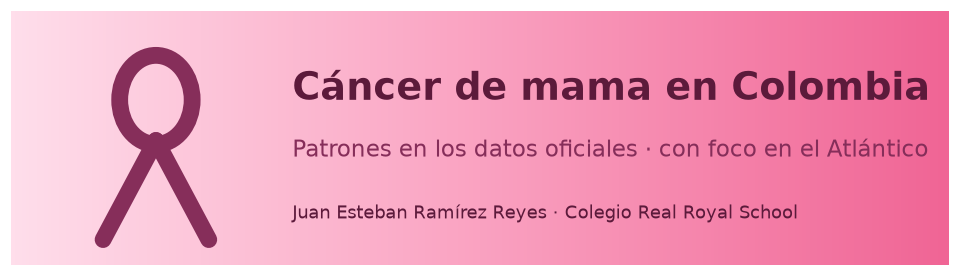

In [2]:
#@title 🎗️ Configuración y paleta rosa (ejecuta esta celda primero)
import os, re, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse, Patch
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

ROSA = dict(oscuro="#862E5A", ciruela="#5C1A3B", fuerte="#D6336C", medio="#F06595",
            claro="#FAA2C1", palido="#FFDEEB", fondo="#FFF5F9", gris="#868E96")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": ROSA["fondo"],
    "axes.edgecolor": ROSA["claro"], "axes.grid": True, "grid.color": ROSA["palido"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlecolor": ROSA["oscuro"], "axes.labelcolor": ROSA["ciruela"],
    "xtick.color": ROSA["ciruela"], "ytick.color": ROSA["ciruela"], "font.size": 11,
    "axes.prop_cycle": plt.cycler(color=[ROSA["fuerte"], ROSA["oscuro"], ROSA["claro"], ROSA["gris"], ROSA["medio"]]),
})

def es(x, d=1):
    """Formato numérico en español: 1.234,5"""
    s = f"{x:,.{d}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")

GRUPOS = ["0-4","5-9","10-14","15-19","20-24","25-29","30-34","35-39","40-44","45-49",
          "50-54","55-59","60-64","65-69","70-74","75-79","80-84","85+"]
# Población estándar mundial OMS 2000-2025 (Ahmad et al., 2001); 85+ agrupa 85 y más
W_OMS = pd.Series([8.86,8.69,8.60,8.47,8.22,7.93,7.61,7.15,6.59,6.04,
                   5.37,4.55,3.72,2.96,2.21,1.52,0.91,0.635], index=GRUPOS)
W_OMS = W_OMS / W_OMS.sum()

# --- Banner ---
fig, ax = plt.subplots(figsize=(11, 3))
ax.imshow(np.linspace(0, 1, 256).reshape(1, -1), extent=[0, 11, 0, 3], aspect="auto",
          cmap=LinearSegmentedColormap.from_list("rosa", [ROSA["palido"], ROSA["claro"], ROSA["medio"]]))
ax.set_xlim(0, 11); ax.set_ylim(0, 3); ax.axis("off")
cx, cy = 1.7, 1.45                                     # lazo rosa (símbolo de la lucha contra el cáncer de mama)
ax.add_patch(Ellipse((cx, cy + 0.5), 0.85, 1.05, fill=False, lw=11, ec=ROSA["oscuro"]))
for sgn in (-1, 1):
    ax.plot([cx, cx + sgn * 0.62], [cy + 0.02, cy - 1.15], color=ROSA["oscuro"], lw=11, solid_capstyle="round")
ax.text(3.3, 1.95, "Cáncer de mama en Colombia", fontsize=25, weight="bold", color=ROSA["ciruela"])
ax.text(3.3, 1.28, "Patrones en los datos oficiales · con foco en el Atlántico", fontsize=15, color=ROSA["oscuro"])
ax.text(3.3, 0.55, "Juan Esteban Ramírez Reyes · Colegio Real Royal School", fontsize=12, color=ROSA["ciruela"])
plt.show()

# 🎗️ Por qué existe este proyecto

Este no es solo un ejercicio de datos.

**Mi tía vivió el cáncer de mama.** **La mamá de mi mejor amiga también.** Y cuando empecé a hablar de este proyecto me di cuenta de algo:
casi todos conocemos a alguien. Una vecina, una profesora, una tía, una mamá, una amiga. Detrás de cada fila de una tabla hay una mujer,
una familia que esperó resultados, una cita que se demoró, un tratamiento que empezó (o no) a tiempo.

Quise usar lo que estoy aprendiendo de ciencia de datos para hacer algo con sentido: **mirar los datos oficiales con rigor y con respeto,
buscar patrones y preguntarme dónde se puede hacer mejor**, sobre todo en mi región, el Atlántico.

> *A mi tía, a la mamá de mi mejor amiga y a todas las mujeres (y a las familias que las acompañan) que han vivido el cáncer de mama:
> este trabajo es para ustedes.*

<!-- Si ellas están de acuerdo, aquí puedes añadir sus nombres o unas palabras sobre ellas. -->

### Mi compromiso con los datos
- Cada número que veas aquí **sale de los tres archivos oficiales**; nada está inventado ni "redondeado a conveniencia".
- Donde los datos **no alcanzan para concluir algo**, lo digo.
- Detrás de cada tasa hay personas: por eso evito sacar conclusiones más fuertes de lo que los datos permiten.

# Contenido
1. Introducción y pregunta de investigación
2. Datos: qué tengo (y qué no)
3. Colombia 2015-2025: ¿crece la carga del cáncer de mama?
4. La pandemia y la mortalidad de las mujeres
5. Demografía: ¿cuántas mujeres estarán en edades de mayor riesgo?
6. **El Atlántico frente al país**
7. Desigualdad por tipo de afiliación (régimen)
8. Cómo llega el diagnóstico: estadio, subtipos y tratamiento
9. ¿Cuánto se demora la atención?
10. Hallazgos y conclusiones por hipótesis
11. Limitaciones y honestidad científica
12. Referencias

# 1. Introducción y pregunta de investigación

El cáncer de mama es uno de los cánceres más frecuentes en las mujeres colombianas. Detectarlo temprano mejora mucho el pronóstico,
pero el acceso al diagnóstico y al tratamiento **no es igual en todo el país**. La Cuenta de Alto Costo (CAC) reúne datos de las mujeres
con cáncer de mama que reportan las aseguradoras; el DANE publica las defunciones y la población.

### Pregunta de investigación
**¿Qué patrones muestran los datos oficiales disponibles sobre el cáncer de mama en Colombia y en el Atlántico, y qué dicen sobre la detección, la atención y las desigualdades?**

### Hipótesis
- **H1 (Atlántico).** En 2025, el Atlántico tiene una tasa de casos nuevos reportados **y** una mortalidad (en mujeres con cáncer de mama) **más altas que el promedio nacional**.
- **H2 (carga en el tiempo).** Entre 2015 y 2025 crecen la prevalencia y los casos nuevos reportados en Colombia; pero la proporción de mujeres con cáncer de mama que muere cada año **no sube** al mismo ritmo.
- **H3 (desigualdad).** El régimen subsidiado reporta **menos casos nuevos** que el contributivo y, aun así, tiene una relación muertes/casos nuevos **más alta**: señal posible de diagnóstico tardío o de subdiagnóstico.
- **H4 (oportunidad).** Los tiempos promedio de atención **superan las metas** en varios tramos del camino, y la espera para confirmar el diagnóstico es peor en el subsidiado.
- **H5 (demografía).** Las mujeres en edades de mayor riesgo (50-74 años) crecen más rápido que el total de mujeres: la presión sobre el sistema aumentaría **aunque el riesgo no cambie**.

### Conceptos clave
| Término | Significado |
|---|---|
| **PCNR** | *Proporción de casos nuevos reportados* (CAC), por 100.000 mujeres. **No es incidencia pura**: depende de qué tan bien se reporte y se detecte. |
| **Prevalencia** | Mujeres que viven con el diagnóstico en el periodo, por 100.000 mujeres. |
| **Mortalidad (CAC)** | Muertes por **cualquier causa** en mujeres con cáncer de mama dentro de la cohorte CAC. **No es mortalidad por cáncer de mama (C50).** |
| **Tasa cruda** | Casos o muertes ÷ mujeres. Depende de cuántas mujeres mayores haya. |
| **Tasa estandarizada** | Tasa "ajustada por edad" para comparar territorios sin que la estructura de edad confunda. |
| **IC 95 %** | Rango plausible de la tasa. Si dos intervalos no se tocan, la diferencia es clara. |

# 2. Datos: qué tengo (y qué no)

Trabajo con **tres archivos oficiales** ya ordenados en formato tabular:

| Archivo | Fuente | Qué aporta |
|---|---|---|
| `cancer_mama_CAC_2025_ordenado.csv` | Cuenta de Alto Costo (informe 2025) | Serie nacional 2015-2025, regiones, régimen, estadio, subtipos, tratamiento y tiempos de atención. **Del Atlántico solo hay el dato 2025.** |
| `defunciones_no_fetales_2008_2026.csv` | DANE, Estadísticas Vitales | Muertes **por todas las causas** según año, edad, sexo y área (nacional). |
| `poblacion_mujeres_nacional_2018_2070.csv` | DANE, proyecciones de población | Mujeres por grupo quinquenal de edad, año y área (nacional). |

In [3]:
def ubicar(nombre):
    """Busca el archivo en carpetas habituales; en Colab, ofrece subirlo."""
    for base in [".", "datos", "data", "/content", "/content/drive/MyDrive", "/mnt/user-data/uploads"]:
        ruta = os.path.join(base, nombre)
        if os.path.exists(ruta):
            return ruta
    try:
        from google.colab import files
        print(f"No encontré '{nombre}'. Súbelo ahora:")
        files.upload()
        if os.path.exists(nombre):
            return nombre
    except ImportError:
        pass
    raise FileNotFoundError(f"Falta '{nombre}'. Ponlo junto al cuaderno. No se usan datos inventados.")

cac  = pd.read_csv(ubicar("cancer_mama_CAC_2025_ordenado.csv"), encoding="utf-8-sig")
dfun = pd.read_csv(ubicar("defunciones_no_fetales_2008_2026.csv"), encoding="utf-8-sig")
pob  = pd.read_csv(ubicar("poblacion_mujeres_nacional_2018_2070.csv"), encoding="utf-8-sig")

assert {"seccion","anio","nivel","categoria","medida","valor","ic95_inf","ic95_sup","nota"} <= set(cac.columns)
assert {"anio","estado_cifra","grupo_edad","area","sexo","defunciones"} <= set(dfun.columns)
assert {"anio","area","sexo","grupo_edad","mujeres"} <= set(pob.columns)

inventario = pd.DataFrame({
    "archivo": ["CAC (cáncer de mama)", "DANE defunciones", "DANE población de mujeres"],
    "filas": [len(cac), len(dfun), len(pob)],
    "años": [f"{cac.anio.min()}–{cac.anio.max()}", f"{dfun.anio.min()}–{dfun.anio.max()}", f"{pob.anio.min()}–{pob.anio.max()}"],
    "territorio": ["Nacional, regiones, régimen y algunos departamentos (2025)", "Nacional", "Nacional"],
    "ojo con": ["Mortalidad = todas las causas en mujeres con cáncer de mama",
                "Todas las causas (no hay causa C50); 2019 preliminar y 2026 parcial",
                "Hay filas por área y una fila 'Total' (no sumar todo: se duplica)"],
})
display(inventario)
display(cac.groupby("seccion").size().rename("filas").to_frame().T)

,archivo,filas,años,territorio,ojo con
0,CAC (cáncer de mama),235,2015–2025,"Nacional, regiones, régimen y algunos departam...",Mortalidad = todas las causas en mujeres con c...
1,DANE defunciones,6840,2008–2026,Nacional,Todas las causas (no hay causa C50); 2019 prel...
2,DANE población de mujeres,2499,2018–2070,Nacional,Hay filas por área y una fila 'Total' (no suma...


seccion,clinica_casos_nuevos,clinica_casos_prevalentes,contexto_poblacion,oportunidad,serie_nacional,tasas_2025_departamento,tasas_2025_regimen,tasas_2025_region,totales_2025,tratamiento_casos_nuevos
filas,31,1,1,8,33,8,56,84,5,8


### ¿Qué NO puedo hacer con estos datos? (y por qué lo digo desde el principio)
- **No puedo calcular la mortalidad específica por cáncer de mama (C50)**: el archivo del DANE no trae la causa de muerte.
- **No puedo analizar Barranquilla ni una serie del Atlántico en el tiempo**: la CAC solo da el dato 2025 para algunos departamentos, y el DANE solo está a nivel nacional.
- **No puedo hacer un pronóstico de muertes por cáncer de mama a 2035.** Sí puedo mostrar cuánta población en edades de riesgo habrá (sección 5).

Todo lo demás se puede hacer, y hay **bastantes patrones interesantes**. 👇

# 3. Colombia 2015-2025: ¿crece la carga del cáncer de mama?

La CAC publica una serie nacional de tres indicadores (por 100.000 mujeres): **prevalencia**, **casos nuevos reportados (PCNR)** y **mortalidad por todas las causas en mujeres con cáncer de mama**.
Añado un indicador propio: **cuántas mujeres mueren por cada 100 que viven con el diagnóstico** (mortalidad ÷ prevalencia).
Si el sistema mejora la supervivencia, esa proporción debería bajar aunque haya más casos.

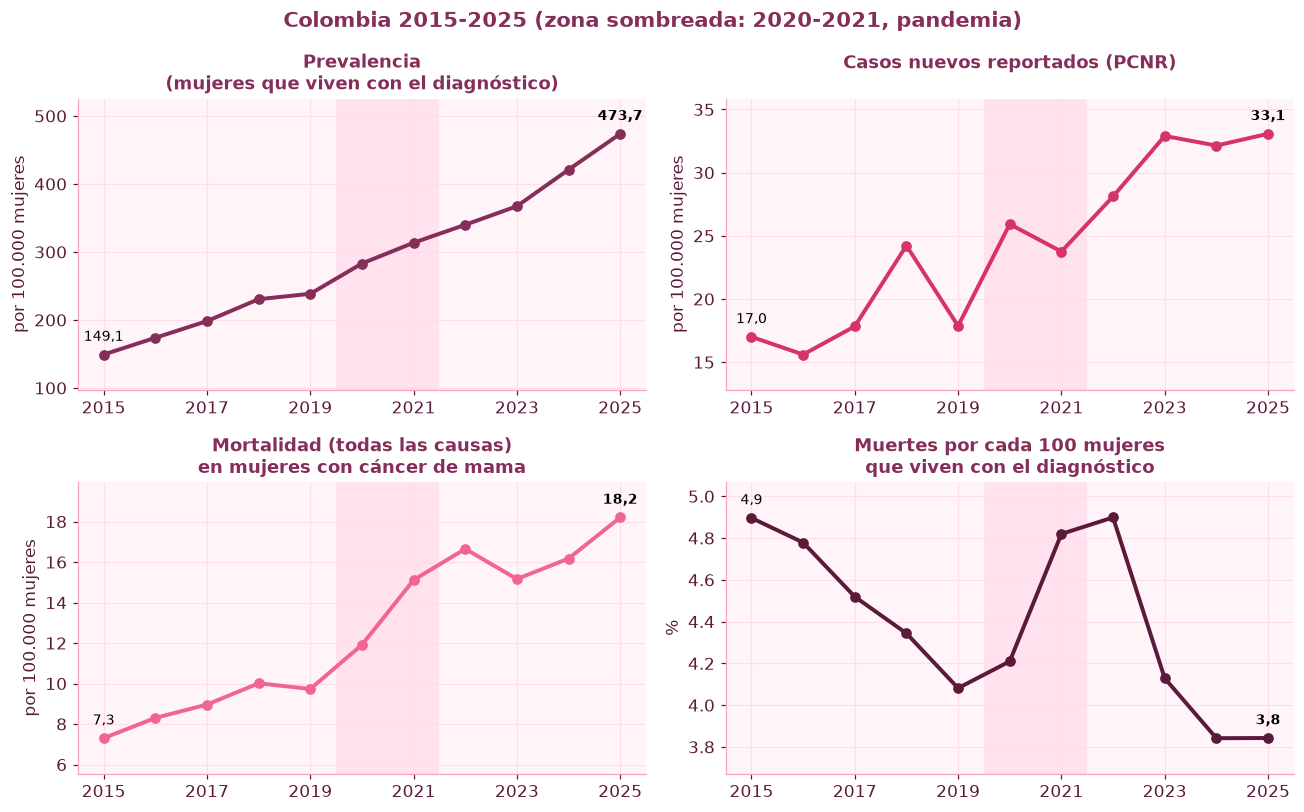

medida,mortalidad_todas_causas_cruda,pcnr_cruda,prevalencia_cruda,muertes_por_100_prevalentes
anio,,,,
2015,7.30,17.00,149.10,4.90
2016,8.30,15.60,173.70,4.78
2017,8.96,17.83,198.28,4.52
2018,10.01,24.22,230.46,4.34
2019,9.73,17.86,238.41,4.08
2020,11.91,25.92,282.94,4.21
2021,15.11,23.75,313.52,4.82
2022,16.65,28.11,339.91,4.90
2023,15.16,32.90,367.21,4.13


Crecimiento anual compuesto 2015→2025 (%): {'prevalencia_cruda': np.float64(12.3), 'pcnr_cruda': np.float64(6.9), 'mortalidad_todas_causas_cruda': np.float64(9.6), 'muertes_por_100_prevalentes': np.float64(-2.4)}


In [4]:
def fila(seccion, medida, categoria=None, nivel=None, anio=None):
    """Devuelve exactamente UNA fila de la tabla CAC (si no, avisa)."""
    q = cac[(cac.seccion == seccion) & (cac.medida == medida)]
    if categoria is not None: q = q[q.categoria == categoria]
    if nivel is not None:     q = q[q.nivel == nivel]
    if anio is not None:      q = q[q.anio == anio]
    assert len(q) == 1, f"Esperaba 1 fila y encontré {len(q)}: {seccion} | {medida} | {categoria}"
    return q.iloc[0]

H = {}   # aquí guardo los resultados clave para las conclusiones

serie = cac[cac.seccion == "serie_nacional"].pivot(index="anio", columns="medida", values="valor")
serie["muertes_por_100_prevalentes"] = serie["mortalidad_todas_causas_cruda"] / serie["prevalencia_cruda"] * 100
cagr = lambda s: ((s.iloc[-1] / s.iloc[0]) ** (1 / (len(s) - 1)) - 1) * 100
H["cagr"] = {c: cagr(serie[c]) for c in ["prevalencia_cruda", "pcnr_cruda", "mortalidad_todas_causas_cruda", "muertes_por_100_prevalentes"]}

paneles = [("prevalencia_cruda", "Prevalencia\n(mujeres que viven con el diagnóstico)", "por 100.000 mujeres", ROSA["oscuro"]),
           ("pcnr_cruda", "Casos nuevos reportados (PCNR)\n ", "por 100.000 mujeres", ROSA["fuerte"]),
           ("mortalidad_todas_causas_cruda", "Mortalidad (todas las causas)\nen mujeres con cáncer de mama", "por 100.000 mujeres", ROSA["medio"]),
           ("muertes_por_100_prevalentes", "Muertes por cada 100 mujeres\nque viven con el diagnóstico", "%", ROSA["ciruela"])]
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (col, tit, un, color) in zip(axs.ravel(), paneles):
    ax.axvspan(2019.5, 2021.5, color=ROSA["palido"], alpha=.8, lw=0)
    ax.plot(serie.index, serie[col], marker="o", color=color, lw=2.6)
    ax.set_title(tit, fontsize=11.5); ax.set_ylabel(un); ax.margins(y=0.16)
    ax.annotate(es(serie[col].iloc[0], 1), (serie.index[0], serie[col].iloc[0]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
    ax.annotate(es(serie[col].iloc[-1], 1), (serie.index[-1], serie[col].iloc[-1]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, weight="bold")
    ax.set_xticks(serie.index[::2])
fig.suptitle("Colombia 2015-2025 (zona sombreada: 2020-2021, pandemia)", color=ROSA["oscuro"], weight="bold", fontsize=14)
plt.tight_layout(); plt.show()

display(serie.round(2))
print("Crecimiento anual compuesto 2015→2025 (%):", {k: round(v, 1) for k, v in H["cagr"].items()})

**Cómo leerlo:** la prevalencia y los casos nuevos reportados suben mucho, y la mortalidad en la cohorte también. Pero **no es lo mismo que "haya más cáncer"**:
parte del aumento puede deberse a que **se reporta y se detecta mejor** (más mujeres ingresan a la cohorte) y a que las mujeres **viven más tiempo con el diagnóstico**
(si sobreviven más, la prevalencia sube). Por eso el cuarto panel es el más informativo: muestra si, **entre las mujeres que viven con el diagnóstico, la proporción que muere cada año** sube o baja.

# 4. La pandemia y la mortalidad de las mujeres

La mortalidad de la CAC cuenta muertes **por cualquier causa**, así que debería reaccionar a lo que le pase a **toda** la mortalidad de las mujeres.
Con el archivo del DANE (todas las causas, mujeres) y la población, calculo la **tasa de mortalidad general** de 2018 a 2025 (cruda y ajustada por edad con la población estándar de la OMS)
y la comparo con la serie de la CAC.

,defunciones,cruda,TAE,estado_cifra
anio,,,,
2018,106074,430.4,340.5,Publicado
2019,109227,434.3,340.1,Preliminar (acumulado)
2020,129287,502.8,392.2,Publicado
2021,157595,604.3,472.8,Publicado
2022,128028,485.9,368.2,Publicado
2023,120749,454.1,340.3,Publicado
2024,124636,464.4,341.0,Publicado
2025,127184,470.1,338.6,Publicado


Defunciones de mujeres con edad desconocida (excluidas de las tasas por edad): {2018: 1, 2019: 3, 2020: 1, 2021: 1, 2022: 2, 2023: 78, 2024: 69, 2025: 32}


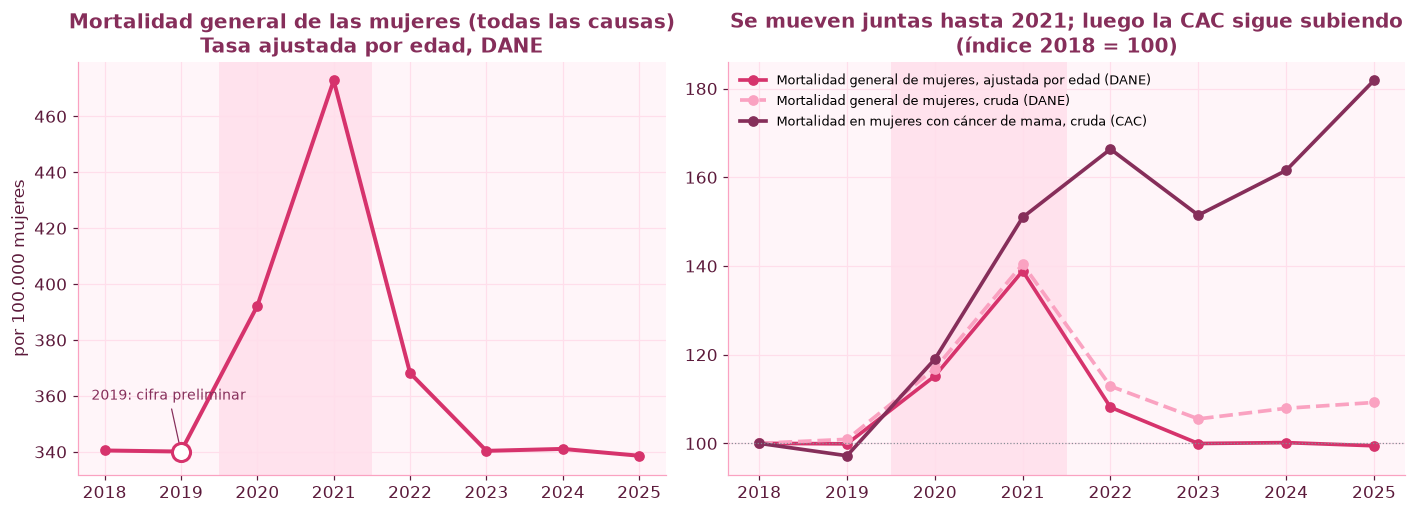

Exceso de mortalidad general (TAE) vs 2018-2019: 2020 = +15.3 %, 2021 = +38.9 %
Correlación CAC vs DANE (n = 8 años; interpretar con cautela): niveles r = 0.32 | cambios anuales r = 0.63


In [5]:
def mapa_edad_def(g):
    infantil = ("Menor 1 hora","De 1 a 23 horas","De 1 a 6 días","De 7 a 27 días","De 28 a 29 días",
                "De 1 a 5 meses","De 6 a 11 meses","De 1 año","De 2 a 4 años")
    if g == "Edad desconocida": return None
    if g in infantil: return "0-4"
    if g == "De 100 años y más": return "85+"
    m = re.match(r"De (\d+) a (\d+) años", g)
    if m: return GRUPOS[min(int(m.group(1)) // 5, 17)]
    raise ValueError(f"Grupo de edad no reconocido: {g}")

mapa_pob = lambda g: "85+" if g in ("85-89", "90-94", "95-99", "100+") else g

# Defunciones de mujeres 2018-2025 (todas las áreas), por grupo quinquenal
dm = dfun[(dfun.sexo == "Mujeres") & dfun.anio.between(2018, 2025)].copy()
dm["gr"] = dm.grupo_edad.map(mapa_edad_def)
desconocida = dm[dm.gr.isna()].groupby("anio").defunciones.sum()
estado = dfun[dfun.anio.between(2018, 2025)].groupby("anio").estado_cifra.first()
dd = dm.dropna(subset=["gr"]).groupby(["anio", "gr"]).defunciones.sum().unstack().reindex(columns=GRUPOS)

# Población de mujeres: SOLO la fila 'Total' (si sumara todas las áreas, duplicaría)
pm = pob[pob.area == "Total"].copy()
pm["gr"] = pm.grupo_edad.map(mapa_pob)
pw = pm.groupby(["anio", "gr"]).mujeres.sum().unstack().reindex(columns=GRUPOS)

tasas_edad = dd / pw.loc[dd.index]
gen = pd.DataFrame({
    "defunciones": dd.sum(axis=1),
    "cruda": dd.sum(axis=1) / pw.loc[dd.index].sum(axis=1) * 1e5,
    "TAE": (tasas_edad * W_OMS.values).sum(axis=1) * 1e5,
    "estado_cifra": estado,
})
display(gen.round(1))
print("Defunciones de mujeres con edad desconocida (excluidas de las tasas por edad):", desconocida.astype(int).to_dict())

base = gen.loc[[2018, 2019], "TAE"].mean()
H["exceso_2021"] = (gen.loc[2021, "TAE"] / base - 1) * 100
H["exceso_2020"] = (gen.loc[2020, "TAE"] / base - 1) * 100

# Comparación (índice 2018 = 100)
idx = pd.DataFrame({
    "Mortalidad general de mujeres, ajustada por edad (DANE)": gen.TAE / gen.TAE.loc[2018] * 100,
    "Mortalidad general de mujeres, cruda (DANE)": gen.cruda / gen.cruda.loc[2018] * 100,
    "Mortalidad en mujeres con cáncer de mama, cruda (CAC)": serie.loc[2018:2025, "mortalidad_todas_causas_cruda"] / serie.loc[2018, "mortalidad_todas_causas_cruda"] * 100,
})
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax = axs[0]
ax.plot(gen.index, gen.TAE, marker="o", color=ROSA["fuerte"], lw=2.6)
ax.scatter([2019], [gen.loc[2019, "TAE"]], s=140, facecolors="white", edgecolors=ROSA["fuerte"], zorder=5, lw=2)
ax.annotate("2019: cifra preliminar", (2019, gen.loc[2019, "TAE"]), textcoords="offset points", xytext=(-8, 34), ha="center", fontsize=9, color=ROSA["oscuro"], arrowprops=dict(arrowstyle="-", color=ROSA["oscuro"], lw=.8))
ax.axvspan(2019.5, 2021.5, color=ROSA["palido"], alpha=.8, lw=0)
ax.set_title("Mortalidad general de las mujeres (todas las causas)\nTasa ajustada por edad, DANE"); ax.set_ylabel("por 100.000 mujeres")
ax = axs[1]
for (nombre, s), c, ls in zip(idx.items(), [ROSA["fuerte"], ROSA["claro"], ROSA["oscuro"]], ["-", "--", "-"]):
    ax.plot(s.index, s.values, marker="o", color=c, lw=2.4, ls=ls, label=nombre)
ax.axvspan(2019.5, 2021.5, color=ROSA["palido"], alpha=.8, lw=0)
ax.axhline(100, color=ROSA["gris"], lw=.8, ls=":")
ax.set_title("Se mueven juntas hasta 2021; luego la CAC sigue subiendo\n(índice 2018 = 100)"); ax.legend(fontsize=8.5, loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

a = idx.iloc[:, 1].values; b = idx.iloc[:, 2].values
H["r_nivel"] = np.corrcoef(a, b)[0, 1]
H["r_cambio"] = np.corrcoef(np.diff(a) / a[:-1], np.diff(b) / b[:-1])[0, 1]
print(f"Exceso de mortalidad general (TAE) vs 2018-2019: 2020 = {H['exceso_2020']:+.1f} %, 2021 = {H['exceso_2021']:+.1f} %")
print(f"Correlación CAC vs DANE (n = 8 años; interpretar con cautela): niveles r = {H['r_nivel']:.2f} | cambios anuales r = {H['r_cambio']:.2f}")

**Lectura:** la mortalidad general de las mujeres subió con fuerza en 2020-2021 y luego volvió a su nivel previo. La mortalidad de las mujeres con cáncer de mama (CAC) tiene un salto en los mismos años,
**lo cual es coherente con que cuente muertes de cualquier causa**, incluida la COVID-19. Es un recordatorio importante: **no debo leer esa serie como "muertes por cáncer de mama"**.
Después de 2022 las dos series se separan: la general regresa a su nivel y la de la cohorte CAC sigue subiendo, algo esperable porque **cada año hay más mujeres viviendo con el diagnóstico** (la cohorte crece, ver prevalencia).
(Con solo 8 años la correlación es una pista, no una prueba.)

Ahora miro la edad: ¿a qué edades mueren las mujeres en Colombia y cómo se compara con la edad típica del diagnóstico?

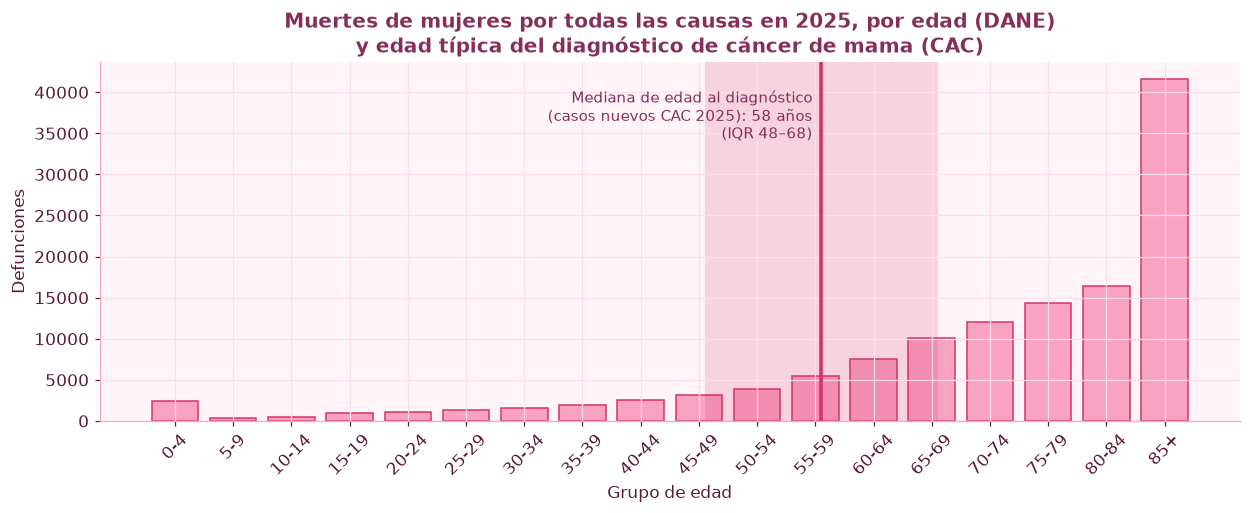

Mediana de edad: casos nuevos = 58 años (IQR 48-68); casos prevalentes = 64 años (IQR 54-72).


In [6]:
ult = 2025
dist = dd.loc[ult]
med_inc, lo_inc, hi_inc = (fila("clinica_casos_nuevos", "mediana_edad", categoria="Casos nuevos", anio=2025)[c] for c in ["valor", "ic95_inf", "ic95_sup"])
med_prev, lo_prev, hi_prev = (fila("clinica_casos_prevalentes", "mediana_edad", anio=2025)[c] for c in ["valor", "ic95_inf", "ic95_sup"])
H["edad_inc"], H["edad_prev"] = (med_inc, lo_inc, hi_inc), (med_prev, lo_prev, hi_prev)

pos = lambda edad: edad / 5 - 0.5          # posición de una edad sobre las barras quinquenales
fig, ax = plt.subplots(figsize=(11.5, 4.8))
ax.bar(range(len(GRUPOS)), dist.values, color=ROSA["claro"], edgecolor=ROSA["fuerte"])
ax.axvspan(pos(lo_inc), pos(hi_inc), color=ROSA["fuerte"], alpha=.18, lw=0)
ax.axvline(pos(med_inc), color=ROSA["fuerte"], lw=2.4)
ax.text(pos(med_inc) - .15, dist.max() * 0.97, f"Mediana de edad al diagnóstico\n(casos nuevos CAC 2025): {med_inc:.0f} años\n(IQR {lo_inc:.0f}–{hi_inc:.0f})",
        ha="right", va="top", fontsize=9.5, color=ROSA["oscuro"])
ax.set_xticks(range(len(GRUPOS))); ax.set_xticklabels(GRUPOS, rotation=45)
ax.set_title(f"Muertes de mujeres por todas las causas en {ult}, por edad (DANE)\ny edad típica del diagnóstico de cáncer de mama (CAC)")
ax.set_xlabel("Grupo de edad"); ax.set_ylabel("Defunciones"); plt.tight_layout(); plt.show()
print(f"Mediana de edad: casos nuevos = {med_inc:.0f} años (IQR {lo_inc:.0f}-{hi_inc:.0f}); casos prevalentes = {med_prev:.0f} años (IQR {lo_prev:.0f}-{hi_prev:.0f}).")

El cáncer de mama se diagnostica en mediana a los **58 años**, pero **una cuarta parte de los casos nuevos se diagnostica antes de los 48** (el borde izquierdo del recuadro rosa).
Para esas mujeres la **detección temprana** y el acceso real a la consulta y a la mamografía cuando notan algo importan muchísimo, aunque no estén aún en la edad de tamización de rutina.

# 5. Demografía: ¿cuántas mujeres estarán en edades de mayor riesgo?

Con la población proyectada del DANE puedo ver cuánto crece el grupo de mujeres de 50 a 74 años (donde se concentra el diagnóstico) comparado con **todas** las mujeres.
**No es un pronóstico de casos ni de muertes**: es una medida de **presión demográfica**. Si el riesgo por edad se mantuviera, el número de mujeres con cáncer de mama crecería *al menos* al ritmo de este grupo.

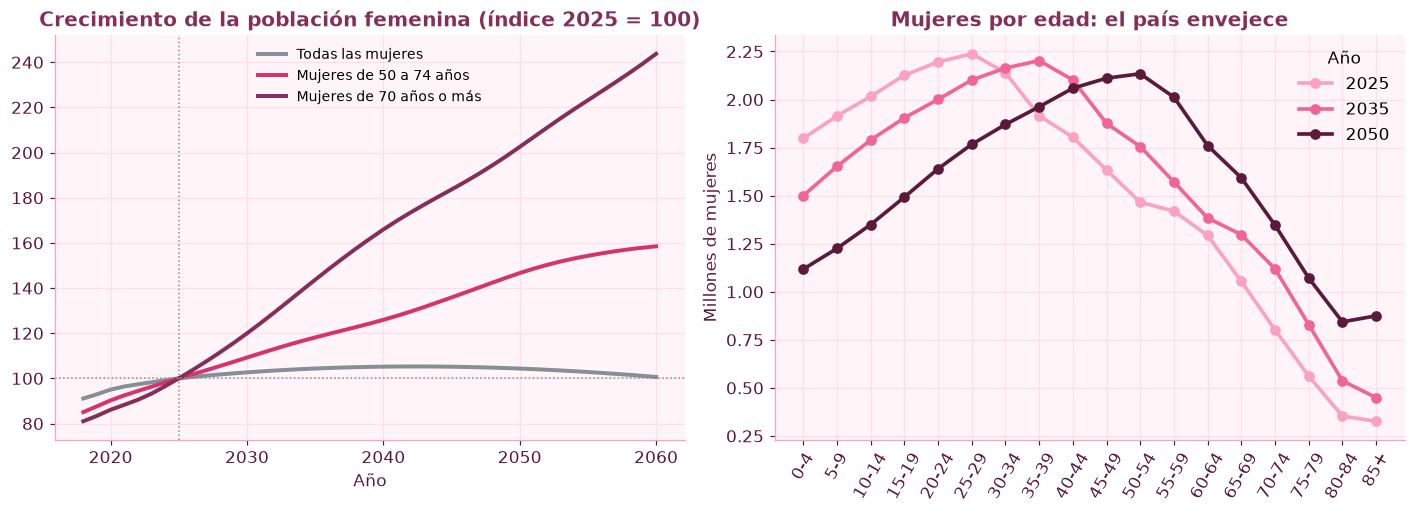

{'Todas las mujeres': '+4.4 % entre 2025 y 2035', 'Mujeres de 50 a 74 años': '+18.1 % entre 2025 y 2035', 'Mujeres de 70 años o más': '+43.6 % entre 2025 y 2035'}
Mujeres de 60 años o más: 16.2 % de las mujeres en 2025 → 26.5 % en 2050. El total de mujeres alcanza su máximo hacia 2042.


In [7]:
tot = pw.sum(axis=1)
g50_74 = pw[["50-54", "55-59", "60-64", "65-69", "70-74"]].sum(axis=1)
g70p = pw[["70-74", "75-79", "80-84", "85+"]].sum(axis=1)
g60p = pw[["60-64", "65-69", "70-74", "75-79", "80-84", "85+"]].sum(axis=1)
BASE, META = 2025, 2035
indice = pd.DataFrame({"Todas las mujeres": tot / tot[BASE] * 100,
                       "Mujeres de 50 a 74 años": g50_74 / g50_74[BASE] * 100,
                       "Mujeres de 70 años o más": g70p / g70p[BASE] * 100}).loc[2018:2060]
H["demo"] = {n: (indice[n].loc[META] - 100) for n in indice}
H["pico_total"] = int(tot.idxmax()); H["share60_2025"] = g60p[BASE] / tot[BASE] * 100; H["share60_2050"] = g60p[2050] / tot[2050] * 100

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axs[0]
for (n, s), c in zip(indice.items(), [ROSA["gris"], ROSA["fuerte"], ROSA["oscuro"]]):
    ax.plot(s.index, s.values, lw=2.6, color=c, label=n)
ax.axvline(BASE, color=ROSA["gris"], ls=":", lw=1); ax.axhline(100, color=ROSA["gris"], ls=":", lw=1)
ax.set_title(f"Crecimiento de la población femenina (índice {BASE} = 100)"); ax.legend(frameon=False, fontsize=9); ax.set_xlabel("Año")
ax = axs[1]
for anio, c in [(2025, ROSA["claro"]), (2035, ROSA["medio"]), (2050, ROSA["ciruela"])]:
    ax.plot(range(len(GRUPOS)), pw.loc[anio].values / 1e6, marker="o", color=c, lw=2.4, label=str(anio))
ax.set_xticks(range(len(GRUPOS))); ax.set_xticklabels(GRUPOS, rotation=60)
ax.set_title("Mujeres por edad: el país envejece"); ax.set_ylabel("Millones de mujeres"); ax.legend(title="Año", frameon=False)
plt.tight_layout(); plt.show()

print({n: f"{v:+.1f} % entre {BASE} y {META}" for n, v in H["demo"].items()})
print(f"Mujeres de 60 años o más: {H['share60_2025']:.1f} % de las mujeres en {BASE} → {H['share60_2050']:.1f} % en 2050. "
      f"El total de mujeres alcanza su máximo hacia {H['pico_total']}.")

**Lectura:** el total de mujeres casi no crece, pero **las que están en las edades de mayor riesgo sí**, y mucho más rápido. Es el mismo fenómeno que hace que **las tasas crudas suban aunque el riesgo por edad no cambie**.
Aun si el riesgo se mantuviera igual, el sistema de salud tendría que atender a más mujeres con cáncer de mama cada año.

# 6. El Atlántico frente al país 🌊

Esta es la parte que más me importa. La CAC da, para 2025, las **tasas estandarizadas por edad** de casos nuevos reportados y de mortalidad (todas las causas, en mujeres con cáncer de mama) para
Colombia, las regiones y algunos departamentos destacados. Al estar estandarizadas, **se pueden comparar** sin que la edad confunda.

**Cuidado con tres cosas:** (1) para los departamentos el informe solo muestra algunos (los más altos y los más bajos), así que no es el ranking completo; (2) el Atlántico hace parte de la región Caribe; (3) San Andrés tiene la tasa de mortalidad más alta, pero según la propia nota del informe **con solo 8 muertes**, así que es muy inestable. El Atlántico es, en la práctica, el departamento de mortalidad más alta entre los que tienen cifras sólidas.

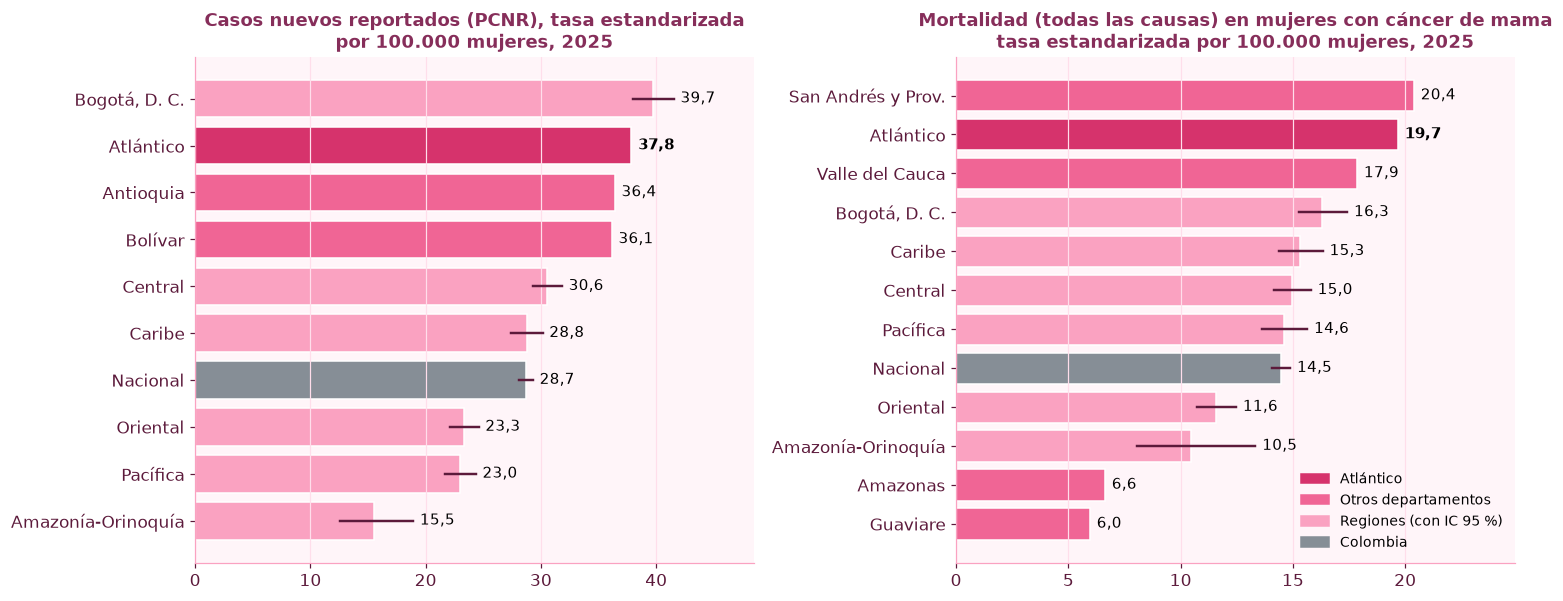

Atlántico vs Colombia → casos nuevos: 37.84 vs 28.69 (x1.32) | mortalidad: 19.68 vs 14.46 (x1.36)
Atlántico vs región Caribe → casos nuevos x1.32 | mortalidad x1.28


In [8]:
def tabla_tasa(medida):
    reg = cac[(cac.seccion == "tasas_2025_region") & (cac.medida == medida)]
    dep = cac[(cac.seccion == "tasas_2025_departamento") & (cac.medida == medida)]
    return pd.concat([reg, dep])[["nivel", "categoria", "valor", "ic95_inf", "ic95_sup"]].reset_index(drop=True)

corto = {"San Andrés, Providencia y Santa Catalina": "San Andrés y Prov.", "Amazonía-Orinoquía": "Amazonía-Orinoquía"}

def barras_h(ax, df, titulo):
    df = df.sort_values("valor").reset_index(drop=True)
    colores = [ROSA["gris"] if r.nivel == "Nacional" else ROSA["fuerte"] if r.categoria == "Atlántico"
               else ROSA["medio"] if r.nivel == "Departamento" else ROSA["claro"] for r in df.itertuples()]
    ax.barh(range(len(df)), df.valor, color=colores, edgecolor="white")
    for i, r in enumerate(df.itertuples()):
        fin = r.valor
        if pd.notna(r.ic95_inf):
            ax.plot([r.ic95_inf, r.ic95_sup], [i, i], color=ROSA["ciruela"], lw=1.6)
            fin = r.ic95_sup
        ax.text(fin + df.valor.max() * .015, i, es(r.valor, 1), va="center", fontsize=9.5,
                weight="bold" if r.categoria == "Atlántico" else "normal")
    ax.set_yticks(range(len(df))); ax.set_yticklabels([corto.get(c, c) for c in df.categoria])
    ax.set_title(titulo, fontsize=11.5); ax.set_xlim(0, df.valor.max() * 1.22); ax.grid(axis="y", visible=False)

inc = tabla_tasa("pcnr_estandarizada")
mor = tabla_tasa("mortalidad_todas_causas_estandarizada")
leyenda = [Patch(color=ROSA["fuerte"], label="Atlántico"), Patch(color=ROSA["medio"], label="Otros departamentos"),
           Patch(color=ROSA["claro"], label="Regiones (con IC 95 %)"), Patch(color=ROSA["gris"], label="Colombia")]
fig, axs = plt.subplots(1, 2, figsize=(14, 5.6))
barras_h(axs[0], inc, "Casos nuevos reportados (PCNR), tasa estandarizada\npor 100.000 mujeres, 2025")
barras_h(axs[1], mor, "Mortalidad (todas las causas) en mujeres con cáncer de mama\ntasa estandarizada por 100.000 mujeres, 2025")
axs[1].legend(handles=leyenda, loc="lower right", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

get = lambda df, cat: float(df.loc[df.categoria == cat, "valor"].iloc[0])
A_inc, A_mor = get(inc, "Atlántico"), get(mor, "Atlántico")
N_inc, N_mor = get(inc, "Nacional"), get(mor, "Nacional")
C_inc, C_mor = get(inc, "Caribe"), get(mor, "Caribe")
H["atl"] = dict(inc=A_inc, mor=A_mor, rr_inc=A_inc / N_inc, rr_mor=A_mor / N_mor,
                rr_inc_car=A_inc / C_inc, rr_mor_car=A_mor / C_mor, mi_atl=A_mor / A_inc, mi_nac=N_mor / N_inc, mi_car=C_mor / C_inc)
print(f"Atlántico vs Colombia → casos nuevos: {A_inc:.2f} vs {N_inc:.2f} (x{H['atl']['rr_inc']:.2f}) | mortalidad: {A_mor:.2f} vs {N_mor:.2f} (x{H['atl']['rr_mor']:.2f})")
print(f"Atlántico vs región Caribe → casos nuevos x{H['atl']['rr_inc_car']:.2f} | mortalidad x{H['atl']['rr_mor_car']:.2f}")

### ¿Más casos reportados significa más muertes? La relación entre ambas
Un territorio puede tener **muchos casos reportados** porque detecta bien (eso es buena noticia) y **pocas muertes**. Si en cambio tiene muchos casos **y** mucha mortalidad, el problema parece más profundo.
Comparo las regiones: eje horizontal = casos nuevos reportados; eje vertical = mortalidad. Calculo también el cociente **mortalidad ÷ casos nuevos** (tasas estandarizadas), una pista (no una medida exacta) de qué tan bien le va al territorio una vez que la mujer está diagnosticada.

,casos_nuevos,mortalidad,mortalidad_por_caso_nuevo
categoria,,,
Amazonía-Orinoquía,15.53,10.47,0.67
Pacífica,22.98,14.60,0.64
Caribe,28.76,15.33,0.53
Nacional,28.69,14.46,0.50
Oriental,23.30,11.59,0.50
Central,30.56,14.96,0.49
"Bogotá, D. C.",39.73,16.30,0.41


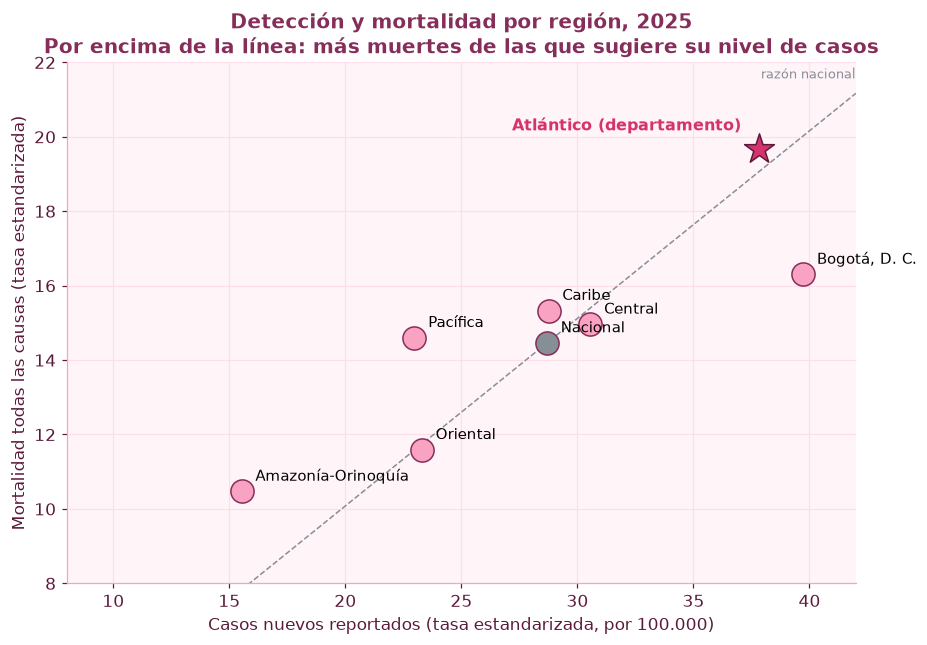


**Lo que se ve:** el Atlántico (estrella) es el punto más alto del gráfico (más mortalidad que cualquier región). Su cociente mortalidad ÷ casos nuevos es **0,52**, casi idéntico al nacional: **su mayor mortalidad es proporcional a sus mayores casos reportados**, no sobra mortalidad dado su nivel de casos (nacional: 0,50).
Entre las regiones, la correlación de rangos entre casos reportados y ese cociente es **-0,94** (6 puntos: es una pista, no una prueba). Las regiones que reportan **menos** casos (Amazonía-Orinoquía, Pacífica) son las que tienen **más muertes por caso**, algo coherente con que parte de los casos no se detecten.

Estos datos **no pueden separar** "el Atlántico detecta más" de "el Atlántico enferma más o diagnostica más tarde". Para distinguirlo harían falta el estadio y los tiempos de atención **por departamento** (sección 12).


In [9]:
regs = (inc[inc.nivel.isin(["Región", "Nacional"])].set_index("categoria")["valor"].rename("casos_nuevos").to_frame()
        .join(mor[mor.nivel.isin(["Región", "Nacional"])].set_index("categoria")["valor"].rename("mortalidad")))
regs["mortalidad_por_caso_nuevo"] = regs.mortalidad / regs.casos_nuevos
display(regs.sort_values("mortalidad_por_caso_nuevo", ascending=False).round(2))

fig, ax = plt.subplots(figsize=(8.6, 6))
for nombre, r in regs.iterrows():
    c = ROSA["gris"] if nombre == "Nacional" else ROSA["claro"]
    ax.scatter(r.casos_nuevos, r.mortalidad, s=230, color=c, edgecolor=ROSA["oscuro"], zorder=3)
    ax.annotate(nombre, (r.casos_nuevos, r.mortalidad), textcoords="offset points", xytext=(9, 7), fontsize=10)
ax.scatter(A_inc, A_mor, s=420, marker="*", color=ROSA["fuerte"], edgecolor=ROSA["ciruela"], zorder=4)
ax.annotate("Atlántico (departamento)", (A_inc, A_mor), textcoords="offset points", xytext=(-12, 12), ha="right", fontsize=10.5, weight="bold", color=ROSA["fuerte"])
xs = np.linspace(8, 42, 10)
ax.plot(xs, xs * H["atl"]["mi_nac"], color=ROSA["gris"], ls="--", lw=1)
ax.text(xs[-1], xs[-1] * H["atl"]["mi_nac"] + .4, "razón nacional", fontsize=8.5, color=ROSA["gris"], ha="right")
ax.set_xlim(8, 42); ax.set_ylim(8, 22)
ax.set_xlabel("Casos nuevos reportados (tasa estandarizada, por 100.000)"); ax.set_ylabel("Mortalidad todas las causas (tasa estandarizada)")
ax.set_title("Detección y mortalidad por región, 2025\nPor encima de la línea: más muertes de las que sugiere su nivel de casos")
plt.tight_layout(); plt.show()

rho = regs.drop("Nacional")[["casos_nuevos", "mortalidad_por_caso_nuevo"]].corr(method="spearman").iloc[0, 1]
H["rho_reg"] = rho
dif = abs(H["atl"]["mi_atl"] - H["atl"]["mi_nac"])
frase_atl = ("casi idéntico al nacional: **su mayor mortalidad es proporcional a sus mayores casos reportados**, no sobra mortalidad dado su nivel de casos"
             if dif < 0.05 else ("más alto que el nacional: hay más muertes de las que sugiere su nivel de casos" if H["atl"]["mi_atl"] > H["atl"]["mi_nac"]
                                 else "más bajo que el nacional"))
display(Markdown(f"""
**Lo que se ve:** el Atlántico (estrella) es el punto más alto del gráfico (más mortalidad que cualquier región). Su cociente mortalidad ÷ casos nuevos es **{es(H['atl']['mi_atl'],2)}**, {frase_atl} (nacional: {es(H['atl']['mi_nac'],2)}).
Entre las regiones, la correlación de rangos entre casos reportados y ese cociente es **{es(rho,2)}** (6 puntos: es una pista, no una prueba). Las regiones que reportan **menos** casos (Amazonía-Orinoquía, Pacífica) son las que tienen **más muertes por caso**, algo coherente con que parte de los casos no se detecten.

Estos datos **no pueden separar** "el Atlántico detecta más" de "el Atlántico enferma más o diagnostica más tarde". Para distinguirlo harían falta el estadio y los tiempos de atención **por departamento** (sección 12).
"""))

# 7. Desigualdad por tipo de afiliación (régimen)

En Colombia el **régimen contributivo** cubre a quienes cotizan y el **subsidiado** a quienes el Estado ayuda a asegurar. Comparo las tasas estandarizadas de 2025:
cuántos casos nuevos se reportan, cuántas mujeres viven con el diagnóstico y cuántas mueren (en la cohorte).

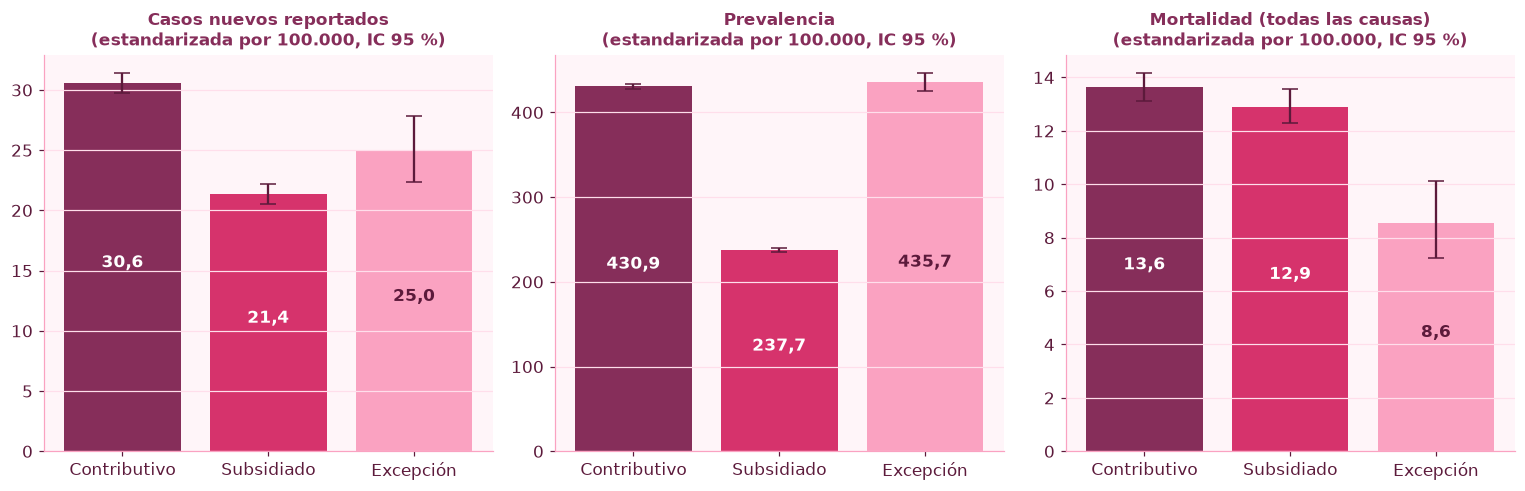

,Casos nuevos reportados,Prevalencia,Mortalidad (todas las causas),Muertes por cada punto de casos nuevos
régimen,,,,
Contributivo,30.56,430.93,13.63,0.45
Subsidiado,21.35,237.71,12.91,0.60
Excepción,24.96,435.67,8.56,0.34


Casos nuevos: subsidiado 21.4 vs contributivo 30.6 | ¿IC 95 % separados? sí
Mortalidad por cada punto de casos nuevos: subsidiado 0.60 vs contributivo 0.45


In [10]:
regimenes = ["Contributivo", "Subsidiado", "Excepción"]
medidas = {"pcnr_estandarizada": "Casos nuevos reportados", "prevalencia_estandarizada": "Prevalencia", "mortalidad_todas_causas_estandarizada": "Mortalidad (todas las causas)"}
filas = []
for rg in regimenes:
    d = {"régimen": rg}
    for m, nom in medidas.items():
        r = fila("tasas_2025_regimen", m, categoria=rg)
        d[nom], d[nom + "_lo"], d[nom + "_hi"] = r.valor, r.ic95_inf, r.ic95_sup
    filas.append(d)
rg_df = pd.DataFrame(filas).set_index("régimen")
rg_df["Muertes por cada punto de casos nuevos"] = rg_df["Mortalidad (todas las causas)"] / rg_df["Casos nuevos reportados"]
H["reg"] = rg_df

fig, axs = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (m, nom) in zip(axs, medidas.items()):
    y = rg_df[nom].values
    err = [y - rg_df[nom + "_lo"].values, rg_df[nom + "_hi"].values - y]
    ax.bar(regimenes, y, color=[ROSA["oscuro"], ROSA["fuerte"], ROSA["claro"]], yerr=err, capsize=5, ecolor=ROSA["ciruela"])
    for i, v in enumerate(y): ax.text(i, v * .5, es(v, 1), ha="center", color="white" if i < 2 else ROSA["ciruela"], weight="bold")
    ax.set_title(nom + "\n(estandarizada por 100.000, IC 95 %)", fontsize=11); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
display(rg_df[["Casos nuevos reportados", "Prevalencia", "Mortalidad (todas las causas)", "Muertes por cada punto de casos nuevos"]].round(2))

c, s = rg_df.loc["Contributivo"], rg_df.loc["Subsidiado"]
H["reg_sep_inc"] = s["Casos nuevos reportados_hi"] < c["Casos nuevos reportados_lo"]
H["reg_ratio"] = (s["Muertes por cada punto de casos nuevos"], c["Muertes por cada punto de casos nuevos"])
print(f"Casos nuevos: subsidiado {s['Casos nuevos reportados']:.1f} vs contributivo {c['Casos nuevos reportados']:.1f} | "
      f"¿IC 95 % separados? {'sí' if H['reg_sep_inc'] else 'no'}")
print(f"Mortalidad por cada punto de casos nuevos: subsidiado {s['Muertes por cada punto de casos nuevos']:.2f} vs contributivo {c['Muertes por cada punto de casos nuevos']:.2f}")

**Patrón que se ve:** el subsidiado reporta **bastantes menos casos nuevos** que el contributivo, pero su mortalidad es **casi igual**. Eso hace que, por cada caso reportado, haya **más muertes** en el subsidiado.
No prueba una causa, pero **es coherente con que parte de los casos del subsidiado no se estén detectando o se detecten tarde**. Es exactamente el tipo de desigualdad que vale la pena investigar con más datos.

# 8. Cómo llega el diagnóstico: estadio, subtipos y tratamiento

El **estadio** al momento del diagnóstico es una de las cosas que más cambia el pronóstico. Estadio I y II suelen significar enfermedad localizada; III y IV, más avanzada.

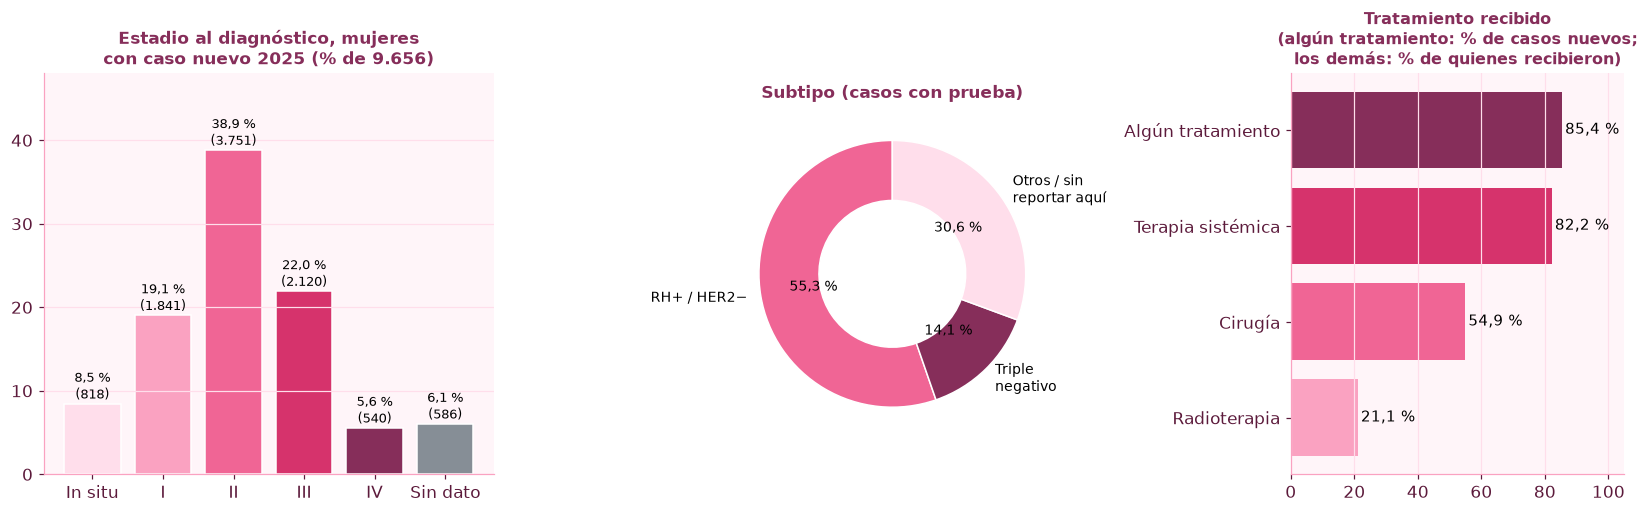

Estadios I-II: 57.9 % | III-IV: 27.6 % | sin dato de estadio: 6.1 % | in situ: 8.5 %
Entre quienes tienen estadio conocido (I-IV): 67.8 % está en estadio I-II.


In [11]:
est = cac[(cac.seccion == "clinica_casos_nuevos") & (cac.nivel == "estadio")]
casos_e = est[est.medida == "casos"].set_index("categoria")["valor"]
pct_e = est[est.medida == "porcentaje"].set_index("categoria")["valor"]
orden = ["In situ", "Estadio I", "Estadio II", "Estadio III", "Estadio IV", "Desconocido"]
pct_e = pct_e.reindex(orden); casos_e = casos_e.reindex(orden)

temprano = pct_e[["Estadio I", "Estadio II"]].sum()
avanzado = pct_e[["Estadio III", "Estadio IV"]].sum()
conocido = casos_e[["Estadio I", "Estadio II", "Estadio III", "Estadio IV"]]
H["estadio"] = dict(temprano=temprano, avanzado=avanzado, desconocido=pct_e["Desconocido"], insitu=pct_e["In situ"],
                    temprano_entre_estadificados=conocido[["Estadio I", "Estadio II"]].sum() / conocido.sum() * 100)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw=dict(width_ratios=[1.35, 1, 1]))
ax = axs[0]
cols = [ROSA["palido"], ROSA["claro"], ROSA["medio"], ROSA["fuerte"], ROSA["oscuro"], ROSA["gris"]]
ax.bar(range(6), pct_e.values, color=cols, edgecolor="white")
for i, (p, n) in enumerate(zip(pct_e.values, casos_e.values)):
    ax.text(i, p + .6, f"{es(p,1)} %\n({es(n, 0)})", ha="center", fontsize=8.5)
ax.set_xticks(range(6)); ax.set_xticklabels(["In situ", "I", "II", "III", "IV", "Sin dato"]); ax.set_ylim(0, 48)
ax.set_title("Estadio al diagnóstico, mujeres\ncon caso nuevo 2025 (% de 9.656)", fontsize=11); ax.grid(axis="x", visible=False)

sub = cac[(cac.seccion == "clinica_casos_nuevos") & (cac.nivel == "Subtipo")].set_index("categoria")["valor"]
valores = [sub["RH+ / HER2-"], sub["RH- / HER2- (triple negativo)"]]; valores.append(100 - sum(valores))
axs[1].pie(valores, labels=["RH+ / HER2−", "Triple\nnegativo", "Otros / sin\nreportar aquí"], colors=[ROSA["medio"], ROSA["oscuro"], ROSA["palido"]],
           autopct=lambda p: f"{es(p,1)} %", startangle=90, wedgeprops=dict(width=.45, edgecolor="white"), textprops=dict(fontsize=9))
axs[1].set_title("Subtipo (casos con prueba)", fontsize=11)

tr = cac[(cac.seccion == "tratamiento_casos_nuevos") & (cac.medida == "porcentaje")].set_index("categoria")["valor"]
tr = tr.reindex(["Algún tratamiento", "Terapia sistémica", "Cirugía", "Radioterapia"])
axs[2].barh(range(4)[::-1], tr.values, color=[ROSA["oscuro"], ROSA["fuerte"], ROSA["medio"], ROSA["claro"]])
for i, v in zip(range(4)[::-1], tr.values): axs[2].text(v + 1, i, f"{es(v,1)} %", va="center", fontsize=9.5)
axs[2].set_yticks(range(4)[::-1]); axs[2].set_yticklabels(tr.index); axs[2].set_xlim(0, 105); axs[2].grid(axis="y", visible=False)
axs[2].set_title("Tratamiento recibido\n(algún tratamiento: % de casos nuevos;\nlos demás: % de quienes recibieron)", fontsize=10.5)
plt.tight_layout(); plt.show()

print(f"Estadios I-II: {temprano:.1f} % | III-IV: {avanzado:.1f} % | sin dato de estadio: {pct_e['Desconocido']:.1f} % | in situ: {pct_e['In situ']:.1f} %")
print(f"Entre quienes tienen estadio conocido (I-IV): {H['estadio']['temprano_entre_estadificados']:.1f} % está en estadio I-II.")

**Lectura:** casi 6 de cada 10 casos nuevos llegan en estadios I-II, pero **más de 1 de cada 4 llega en estadios III-IV**. Ese grupo es donde el tratamiento suele ser más largo, más complejo y con peor pronóstico.
La edad mediana en que se diagnostica es 58 años (y 64 en las mujeres que ya viven con el diagnóstico), lo que muestra que **muchas mujeres conviven años con la enfermedad**: por eso importan tanto el acompañamiento y el seguimiento.

# 9. ¿Cuánto se demora la atención?

La CAC mide los **días promedio** entre pasos del camino de una paciente (desde la consulta por síntomas hasta el primer tratamiento) y los compara con **metas** de oportunidad.
Un día extra para una mujer con cáncer no es "un día más": es incertidumbre, angustia y tiempo para que la enfermedad avance.

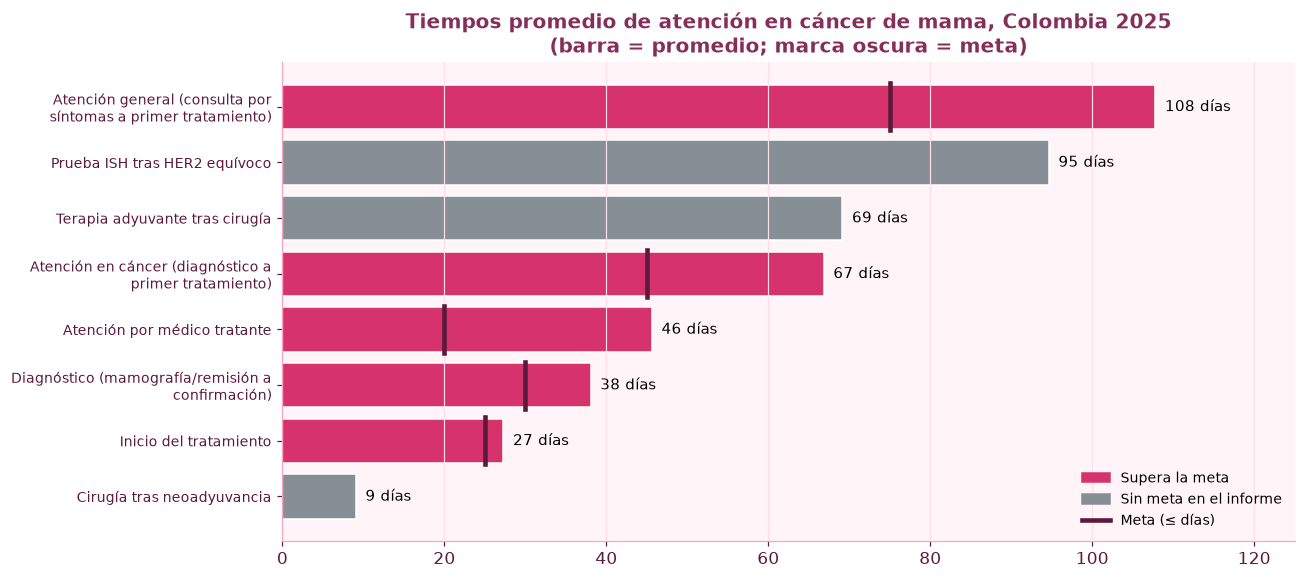

5 de 5 tramos con meta superan la meta.
- Inicio del tratamiento: contributivo 27.3 días | subsidiado 26.8 días | meta ≤25
- Diagnóstico (mamografía/remisión a confirmación): contributivo 34.0 días | subsidiado 49.1 días | meta ≤30


In [12]:
op = cac[cac.seccion == "oportunidad"].copy()
op["meta"] = op.nota.str.extract(r"Meta ≤(\d+)")[0].astype(float)
op = op.sort_values("valor")
op["etiqueta"] = op.categoria.map(lambda t: "\n".join(textwrap.wrap(t, 38)))
op["cumple"] = np.where(op.meta.isna(), np.nan, (op.valor <= op.meta).astype(float))

fig, ax = plt.subplots(figsize=(12, 5.4))
cols = [ROSA["gris"] if np.isnan(m) else (ROSA["claro"] if c == 1 else ROSA["fuerte"]) for m, c in zip(op.meta, op.cumple)]
ax.barh(range(len(op)), op.valor, color=cols, edgecolor="white")
for i, r in enumerate(op.itertuples()):
    ax.text(r.valor + 1.2, i, f"{r.valor:.0f} días", va="center", fontsize=9.5)
    if not np.isnan(r.meta):
        ax.plot([r.meta, r.meta], [i - .42, i + .42], color=ROSA["ciruela"], lw=3)
ax.set_yticks(range(len(op))); ax.set_yticklabels(op.etiqueta, fontsize=9); ax.set_xlim(0, 125)
ax.legend(handles=[Patch(color=ROSA["fuerte"], label="Supera la meta")] + ([Patch(color=ROSA["claro"], label="Dentro de la meta")] if (op.cumple == 1).any() else []) +
                  [Patch(color=ROSA["gris"], label="Sin meta en el informe"), plt.Line2D([0], [0], color=ROSA["ciruela"], lw=3, label="Meta (≤ días)")],
          frameon=False, loc="lower right", fontsize=9)
ax.set_title("Tiempos promedio de atención en cáncer de mama, Colombia 2025\n(barra = promedio; marca oscura = meta)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

con_meta = op.dropna(subset=["meta"])
H["op"] = dict(n=len(con_meta), supera=int((con_meta.valor > con_meta.meta).sum()),
               general=float(op.loc[op.categoria.str.startswith("Atención general"), "valor"].iloc[0]),
               meta_general=float(op.loc[op.categoria.str.startswith("Atención general"), "meta"].iloc[0]))
# Diferencias por régimen: están escritas en la nota del informe ("Contributivo 33,96; subsidiado 49,10")
reg_op = {}
for r in op.dropna(subset=["nota"]).itertuples():
    m = re.search(r"Contributivo ([\d,]+); subsidiado ([\d,]+)", r.nota)
    if m: reg_op[r.categoria] = (float(m.group(1).replace(",", ".")), float(m.group(2).replace(",", ".")), r.meta)
H["op_reg"] = reg_op
print(f"{H['op']['supera']} de {H['op']['n']} tramos con meta superan la meta.")
for k, (cont, subs, meta) in reg_op.items():
    print(f"- {k}: contributivo {cont:.1f} días | subsidiado {subs:.1f} días | meta ≤{meta:.0f}")

**Lectura:** el camino completo desde que la mujer consulta por síntomas hasta el primer tratamiento supera la meta nacional con holgura.
Y en el paso de **confirmar el diagnóstico** (mamografía o remisión → confirmación) la espera en el subsidiado es bastante mayor que en el contributivo (en el **inicio del tratamiento**, en cambio, no hay diferencia entre regímenes).
Ese primer tramo es crítico: **es donde una mujer puede quedarse esperando sin saber qué tiene**.

# 10. Hallazgos y conclusiones por hipótesis

Todas las cifras de esta sección se **generan automáticamente** a partir de los cálculos de arriba (nada escrito a mano).

In [13]:
a, rg = H["atl"], H["reg"]
c, s = rg.loc["Contributivo"], rg.loc["Subsidiado"]
cg = H["cagr"]
m15, m25 = serie["muertes_por_100_prevalentes"].iloc[0], serie["muertes_por_100_prevalentes"].iloc[-1]
d_reg = H["op_reg"].get("Diagnóstico (mamografía/remisión a confirmación)")

def veredicto(ok, parcial=False):
    return "✅ **Se apoya**" if ok else ("🟡 **Se apoya en parte**" if parcial else "❌ **No se apoya**")

h1 = a["rr_inc"] > 1 and a["rr_mor"] > 1
h2 = cg["prevalencia_cruda"] > 0 and cg["pcnr_cruda"] > 0 and m25 < m15
h3 = (s["Casos nuevos reportados"] < c["Casos nuevos reportados"]) and (H["reg_ratio"][0] > H["reg_ratio"][1])
h4 = H["op"]["supera"] > 0 and d_reg is not None and d_reg[1] > d_reg[0]
h5 = H["demo"]["Mujeres de 50 a 74 años"] > H["demo"]["Todas las mujeres"]

display(Markdown(f"""
### Resumen en una mirada
- **Atlántico:** casos nuevos reportados **{es(a['inc'],1)}** (x{es(a['rr_inc'],2)} el nacional) y mortalidad en mujeres con cáncer de mama **{es(a['mor'],1)}** (x{es(a['rr_mor'],2)} el nacional), por 100.000 mujeres, tasas estandarizadas 2025.
- **Colombia 2015→2025:** la prevalencia crece **{es(cg['prevalencia_cruda'],1)} % al año**, los casos nuevos reportados **{es(cg['pcnr_cruda'],1)} %** y la mortalidad de la cohorte **{es(cg['mortalidad_todas_causas_cruda'],1)} %**; las muertes por cada 100 mujeres que viven con el diagnóstico pasan de **{es(m15,1)} a {es(m25,1)}**.
- **Régimen:** casos nuevos {es(s['Casos nuevos reportados'],1)} (subsidiado) vs {es(c['Casos nuevos reportados'],1)} (contributivo); mortalidad {es(s['Mortalidad (todas las causas)'],1)} vs {es(c['Mortalidad (todas las causas)'],1)}.
- **Estadio:** {es(H['estadio']['temprano'],1)} % en estadios I-II y {es(H['estadio']['avanzado'],1)} % en III-IV al diagnóstico ({es(H['estadio']['desconocido'],1)} % sin dato).
- **Tiempos:** {H['op']['supera']} de {H['op']['n']} tramos con meta la superan; consulta por síntomas → primer tratamiento: **{es(H['op']['general'],0)} días** (meta ≤{es(H['op']['meta_general'],0)}).
- **Demografía:** entre 2025 y 2035 las mujeres de 50-74 años crecen **{es(H['demo']['Mujeres de 50 a 74 años'],1)} %**, frente a **{es(H['demo']['Todas las mujeres'],1)} %** de todas las mujeres.

### Conclusiones por hipótesis
**H1 · Atlántico** — {veredicto(h1)}. El Atlántico supera al país en casos nuevos reportados (x{es(a['rr_inc'],2)}) y en mortalidad (x{es(a['rr_mor'],2)}), y también a la región Caribe (x{es(a['rr_inc_car'],2)} y x{es(a['rr_mor_car'],2)}). No puedo separar "detecta más" de "enferma/llega más tarde", y para departamentos el informe no da intervalos de confianza.

**H2 · Carga en el tiempo** — {veredicto(h2)}. La prevalencia y los casos nuevos reportados crecen con fuerza, y la proporción de mujeres con el diagnóstico que muere cada año baja de {es(m15,1)} a {es(m25,1)} por cada 100. Ojo: una parte del aumento de la prevalencia y de los casos reportados puede ser mejor reporte y detección, no solo más enfermedad.

**H3 · Desigualdad por régimen** — {veredicto(h3)}. El subsidiado reporta menos casos nuevos ({es(s['Casos nuevos reportados'],1)} vs {es(c['Casos nuevos reportados'],1)}), con mortalidad parecida ({es(s['Mortalidad (todas las causas)'],1)} vs {es(c['Mortalidad (todas las causas)'],1)}), así que sus muertes por caso nuevo son mayores ({es(H['reg_ratio'][0],2)} vs {es(H['reg_ratio'][1],2)}). Es una pista de detección tardía o subdiagnóstico, no una prueba.

**H4 · Oportunidad** — {veredicto(h4)}. {H['op']['supera']} de {H['op']['n']} tramos con meta superan la meta. Para confirmar el diagnóstico, el subsidiado espera **{es(d_reg[1],1)} días** frente a **{es(d_reg[0],1)}** del contributivo (meta ≤{es(d_reg[2],0)}); en el inicio del tratamiento no hay diferencia ({es(H['op_reg']['Inicio del tratamiento'][1],1)} vs {es(H['op_reg']['Inicio del tratamiento'][0],1)} días).

**H5 · Demografía** — {veredicto(h5)}. Las mujeres de 50-74 años crecen {es(H['demo']['Mujeres de 50 a 74 años'],1)} % hasta 2035 y las de 70 o más {es(H['demo']['Mujeres de 70 años o más'],1)} %, frente a {es(H['demo']['Todas las mujeres'],1)} % de todas las mujeres.

**Hallazgo extra · la pandemia.** La mortalidad general de las mujeres (ajustada por edad) fue {es(H['exceso_2021'],1)} % mayor en 2021 que el promedio 2018-2019, y la mortalidad de la cohorte CAC también salta en esos años: **recordatorio de que cuenta muertes por cualquier causa**.
"""))


### Resumen en una mirada
- **Atlántico:** casos nuevos reportados **37,8** (x1,32 el nacional) y mortalidad en mujeres con cáncer de mama **19,7** (x1,36 el nacional), por 100.000 mujeres, tasas estandarizadas 2025.
- **Colombia 2015→2025:** la prevalencia crece **12,3 % al año**, los casos nuevos reportados **6,9 %** y la mortalidad de la cohorte **9,6 %**; las muertes por cada 100 mujeres que viven con el diagnóstico pasan de **4,9 a 3,8**.
- **Régimen:** casos nuevos 21,4 (subsidiado) vs 30,6 (contributivo); mortalidad 12,9 vs 13,6.
- **Estadio:** 57,9 % en estadios I-II y 27,6 % en III-IV al diagnóstico (6,1 % sin dato).
- **Tiempos:** 5 de 5 tramos con meta la superan; consulta por síntomas → primer tratamiento: **108 días** (meta ≤75).
- **Demografía:** entre 2025 y 2035 las mujeres de 50-74 años crecen **18,1 %**, frente a **4,4 %** de todas las mujeres.

### Conclusiones por hipótesis
**H1 · Atlántico** — ✅ **Se apoya**. El Atlántico supera al país en casos nuevos reportados (x1,32) y en mortalidad (x1,36), y también a la región Caribe (x1,32 y x1,28). No puedo separar "detecta más" de "enferma/llega más tarde", y para departamentos el informe no da intervalos de confianza.

**H2 · Carga en el tiempo** — ✅ **Se apoya**. La prevalencia y los casos nuevos reportados crecen con fuerza, y la proporción de mujeres con el diagnóstico que muere cada año baja de 4,9 a 3,8 por cada 100. Ojo: una parte del aumento de la prevalencia y de los casos reportados puede ser mejor reporte y detección, no solo más enfermedad.

**H3 · Desigualdad por régimen** — ✅ **Se apoya**. El subsidiado reporta menos casos nuevos (21,4 vs 30,6), con mortalidad parecida (12,9 vs 13,6), así que sus muertes por caso nuevo son mayores (0,60 vs 0,45). Es una pista de detección tardía o subdiagnóstico, no una prueba.

**H4 · Oportunidad** — ✅ **Se apoya**. 5 de 5 tramos con meta superan la meta. Para confirmar el diagnóstico, el subsidiado espera **49,1 días** frente a **34,0** del contributivo (meta ≤30); en el inicio del tratamiento no hay diferencia (26,8 vs 27,3 días).

**H5 · Demografía** — ✅ **Se apoya**. Las mujeres de 50-74 años crecen 18,1 % hasta 2035 y las de 70 o más 43,6 %, frente a 4,4 % de todas las mujeres.

**Hallazgo extra · la pandemia.** La mortalidad general de las mujeres (ajustada por edad) fue 38,9 % mayor en 2021 que el promedio 2018-2019, y la mortalidad de la cohorte CAC también salta en esos años: **recordatorio de que cuenta muertes por cualquier causa**.


# 11. Limitaciones y honestidad científica

- **La mortalidad de la CAC no es mortalidad por cáncer de mama.** Cuenta muertes por *cualquier causa* en mujeres con el diagnóstico.
- **La PCNR no es incidencia.** Depende de qué tan bien se reporta y se detecta; un número alto puede significar buena detección.
- **Atlántico: solo un corte en 2025** (sin tendencia, sin intervalos de confianza en el texto del informe, y solo aparecen algunos departamentos). No puedo hablar de Barranquilla.
- **Datos agregados, no individuales:** no puedo ajustar por edad, estadio, ingresos ni nada más al mismo tiempo; las comparaciones son descriptivas y **no prueban causas**.
- **El DANE está a nivel nacional y por todas las causas.** Sirve para el contexto demográfico, no para estimar muertes por cáncer de mama.
- **2019 es una cifra preliminar, 2026 está incompleta y la población 2018-2070 es una proyección**, no un conteo.
- **Pocos años (8-11) y pocos grupos (6 regiones):** las correlaciones son pistas, no pruebas.
- **No es consejo médico.**

# 🎗️ Para cerrar

Los números no son fríos si uno recuerda de quién hablan. Este proyecto me enseñó que **la detección temprana, el acceso real a la salud y el tiempo de espera** no son temas abstractos: son la diferencia entre una historia y otra.

Si tienes un cambio en la mama (una masa, cambios en la piel o el pezón, secreción), **consulta sin demora**, y si estás en la edad de tamización, **pregunta por tu mamografía**. Y si alguien cercano está pasando por esto, a veces lo más valioso es acompañarla a la cita.

*Con cariño y con datos.*
**Juan Esteban Ramírez Reyes**

# 12. Referencias

> Verifica título, fecha y enlace exactos de cada fuente antes de entregar o publicar.

1. Cuenta de Alto Costo (CAC). Informe sobre cáncer de mama en Colombia (cifras 2025). Datos transcritos de las tablas y figuras indicadas en la columna `tabla_origen` del archivo `cancer_mama_CAC_2025_ordenado.csv`. https://cuentadealtocosto.org
2. DANE. *Estadísticas Vitales (EEVV): defunciones no fetales*. https://www.dane.gov.co
3. DANE. *Proyecciones de población* (base Censo Nacional de Población y Vivienda 2018). https://www.dane.gov.co
4. Ahmad, O. B., et al. (2001). *Age standardization of rates: a new WHO standard.* GPE Discussion Paper Series No. 31. World Health Organization.
5. World Health Organization (2021). *Global Breast Cancer Initiative: Implementation Framework.*